## 0. Préparation

On importe uniquement **NumPy** et **Matplotlib**, présents dans Colab. Les exemples principaux fonctionnent même sans GPU. Les cellules de modèles facultatifs se trouvent à la fin.

In [ ]:
# Importer les bibliothèques nécessaires aux calculs et aux graphiques.
import math
import re
import string
import unicodedata
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

# Définir les couleurs de la présentation (marine et cyan).
MARINE = "#122654"
CYAN = "#08B2CE"
GRIS = "#667085"

# La graine fixe rend les exemples aléatoires reproductibles.
rng = np.random.default_rng(42)

# Nettoyer et découper un texte en mots pour les petits exemples.
def tokens(texte):
    return re.findall(r"\b\w+\b", texte.lower(), flags=re.UNICODE)

# Afficher un score sous une forme facile à lire.
def afficher(nom, valeur):
    print(f"{nom:<25} : {valeur:.3f}")

print("✓ Bibliothèques prêtes — exécution CPU possible")

✓ Bibliothèques prêtes — exécution CPU possible


---
# 1. Summarization — Évaluer un résumé

**Question centrale :** le résumé garde-t-il les informations essentielles **sans inventer de faits** ?

### 1/10 · ROUGE — Recouvrement des mots

**Slide 3.** ROUGE compare le résumé produit avec un **résumé de référence**. Ici, nous calculons **ROUGE-1 rappel** : mots communs / mots de référence. ROUGE-2 compare des bigrammes et ROUGE-L des séquences.

L'exemple est volontairement simple : mêmes mots, mais un mot peut changer complètement le fait rapporté.


In [ ]:
# Les deux phrases reprennent l'exemple de la slide ROUGE.
reference = "Le service a été rétabli après une panne."
genere = "Le service a été rétabli après une attaque."

# Compter le nombre de mots communs en tenant compte des répétitions.
ref_tokens = tokens(reference)
gen_tokens = tokens(genere)
communs = sum((Counter(ref_tokens) & Counter(gen_tokens)).values())

# ROUGE-1 calculé ici en version « rappel », avec une tokenisation simple.
rouge1_rappel = communs / len(ref_tokens)

print("Référence :", reference)
print("Généré   :", genere)
print(f"Mots communs : {communs}/{len(ref_tokens)}")
afficher("ROUGE-1 (rappel)", rouge1_rappel)

Référence : Le service a été rétabli après une panne.
Généré   : Le service a été rétabli après une attaque.
Mots communs : 7/8
ROUGE-1 (rappel)          : 0.875


**Interprétation :** **0,875** paraît excellent, mais « panne » a été remplacé par « attaque ». Le résultat illustre pourquoi **ROUGE ne vérifie pas la vérité des faits**. Ici, nous utilisons un calcul pédagogique et une tokenisation simplifiée, pas une reproduction intégrale des réglages d'un package ROUGE.

### 2/10 · BERTScore — Similarité des mots dans leur contexte

BERTScore utilise un **modèle préentraîné** pour créer des vecteurs de tokens contextualisés, puis compare ces vecteurs. Dans l'exemple suivant, les vecteurs sont **fictifs** : on montre uniquement le calcul de la similarité cosinus, **pas un véritable BERTScore**.

In [ ]:
# Expressions équivalentes provenant de la slide BERTScore.
correspondances = [
    ("entreprise", "société"),
    ("licencié", "supprimé"),
    ("200", "200"),
    ("employés", "postes"),
]

# Simuler deux vecteurs très proches pour chaque paire de termes.
# Ces nombres servent uniquement à illustrer le principe des embeddings.
base = np.array([[1.0, 0.2], [0.2, 1.0], [0.8, 0.8], [-0.5, 0.8]])
reformulation = base + np.array([[0.03, -0.02], [-0.01, 0.02], [0, 0], [0.03, 0.01]])

# Le cosinus mesure la proximité des directions entre deux vecteurs.
def cosinus(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

for (mot_a, mot_b), a, b in zip(correspondances, base, reformulation):
    print(f"{mot_a:>12} ↔ {mot_b:<12} : cosinus simulé = {cosinus(a,b):.3f}")

print("\n⚠ Les scores ci-dessus ne sont PAS des BERTScores : vecteurs artificiels.")

  entreprise ↔ société      : cosinus simulé = 1.000
    licencié ↔ supprimé     : cosinus simulé = 1.000
         200 ↔ 200          : cosinus simulé = 1.000
    employés ↔ postes       : cosinus simulé = 0.999

⚠ Les scores ci-dessus ne sont PAS des BERTScores : vecteurs artificiels.


**Interprétation :** « L’entreprise a licencié 200 employés » et « La société a supprimé 200 postes » peuvent avoir un sens proche malgré un recouvrement lexical limité. Le **vrai BERTScore**, disponible dans la partie optionnelle, utilise des embeddings calculés par un modèle, et non des vecteurs inventés.

### 3/10 · QAFactEval — Vérifier les faits avec des questions

On part d'un **document source**, on pose une question à partir du résumé, puis on compare les réponses. L'exemple est une **simulation manuelle du mécanisme**, pas le système QAFactEval complet.

In [ ]:
# Document d'origine et résumé erroné.
source = "Une panne technique a interrompu les paiements."
resume = "Une cyberattaque a interrompu les paiements."
question = "Quelle est la cause de l'interruption ?"

# Simuler les réponses extraites de la source et du résumé.
reponse_source = "panne technique"
reponse_resume = "cyberattaque"

# Une comparaison simple suffit ici à révéler la contradiction de l'exemple.
coherent = reponse_source.casefold() == reponse_resume.casefold()

print("Source :", source)
print("Résumé :", resume)
print("Question :", question)
print("Réponse source :", reponse_source)
print("Réponse résumé :", reponse_resume)
print("Cohérence sur cet exemple :", "OUI" if coherent else "NON — contradiction")

Source : Une panne technique a interrompu les paiements.
Résumé : Une cyberattaque a interrompu les paiements.
Question : Quelle est la cause de l'interruption ?
Réponse source : panne technique
Réponse résumé : cyberattaque
Cohérence sur cet exemple : NON — contradiction


**Interprétation :** le résumé attribue la panne à une **cyberattaque**, alors que la source parle d'une **panne technique**. QAFactEval automatise ce type de vérification à l'aide de modèles de génération de questions et de QA ; notre test d'égalité n'est qu'une illustration.

---
# 2. Question Answering — Évaluer une réponse

**Question centrale :** la réponse est-elle correcte ? Et si elle s'appuie sur des documents (RAG), les bonnes preuves ont-elles été retrouvées ?

### 4/10 · Exact Match (EM)

**EM = 1** si la réponse et la référence correspondent après normalisation, **0** sinon.

In [ ]:
# Comparer les mêmes réponses que sur la slide Exact Match.
reference_qa = "Trois jours par semaine"
prediction_qa = "Trois jours"

# Normaliser la casse, la ponctuation et les espaces (version pédagogique).
def normaliser(texte):
    texte = texte.casefold()
    texte = "".join(c for c in texte if not unicodedata.category(c).startswith("P"))
    return " ".join(texte.split())

em = int(normaliser(reference_qa) == normaliser(prediction_qa))
print("Référence :", reference_qa)
print("Prédiction :", prediction_qa)
print("Exact Match =", em)

Référence : Trois jours par semaine
Prédiction : Trois jours
Exact Match = 0


**Interprétation :** **EM = 0**, car « par semaine » manque. La métrique est très stricte, même quand la prédiction est partiellement correcte.

### 5/10 · Token F1 — Crédit partiel

Le score F1 combine **précision** (mots prédits correctement) et **rappel** (mots de référence retrouvés).

In [ ]:
# Récupérer les tokens, puis leur intersection avec multiplicité.
r = tokens(normaliser(reference_qa))
p = tokens(normaliser(prediction_qa))
intersection = sum((Counter(r) & Counter(p)).values())

# Calculer précision, rappel et moyenne harmonique.
precision = intersection / len(p) if p else 0.0
rappel = intersection / len(r) if r else 0.0
f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0.0

print(f"Mots en commun : {intersection}")
afficher("Précision", precision)
afficher("Rappel", rappel)
afficher("Token F1", f1)

Mots en commun : 2
Précision                 : 1.000
Rappel                    : 0.500
Token F1                  : 0.667


**Interprétation :** la précision vaut **1**, car les 2 mots prédits apparaissent dans la référence ; le rappel vaut **0,5**, car seuls 2 des 4 mots ont été retrouvés. **F1 ≈ 0,667**.

### 6/10 · Faithfulness — La réponse est-elle soutenue par ses sources ?

On décompose la réponse en affirmations et on vérifie si chaque affirmation est présente ou déductible des documents.

In [ ]:
# Exemple de la présentation : règle RH et réponse d'un assistant.
contexte_rh = "Télétravail : 3 jours par semaine, avec accord du manager."
affirmations = [
    ("Trois jours de télétravail sont autorisés.", True),
    ("Une prime de 100 € est versée.", False),
]

# Les étiquettes True/False sont fournies manuellement après lecture de la source.
soutenues = sum(int(est_soutenue) for _, est_soutenue in affirmations)
faithfulness = soutenues / len(affirmations)
print("Source :", contexte_rh)
for texte, est_soutenue in affirmations:
    print(("✓" if est_soutenue else "✗"), texte)
afficher("Faithfulness (annoté)", faithfulness)

Source : Télétravail : 3 jours par semaine, avec accord du manager.
✓ Trois jours de télétravail sont autorisés.
✗ Une prime de 100 € est versée.
Faithfulness (annoté)     : 0.500


**Interprétation :** **1 affirmation sur 2** est justifiée : **0,50**. Le calcul du ratio est réel, mais les annotations sont **manuelles**. Un évaluateur de type RAGAS peut automatiser la vérification à l'aide d'un modèle.

---
# 3. Text Generation — Évaluer un texte produit

**Question centrale :** le texte est-il prévisible, varié, proche d'écrits humains et utile pour la demande ?

### 7/10 · Perplexity (PPL) — Incertitude d'un modèle de langue

La perplexité s'obtient à partir des **probabilités que le modèle attribue aux tokens effectivement observés** :

\[
\mathrm{PPL}=\exp\left(-\frac{1}{N}\sum_{i=1}^{N}\log p(w_i\mid w_{<i})\right)
\]

Les probabilités ci-dessous sont **inventées pour démontrer la formule**, pas prédites par GPT.

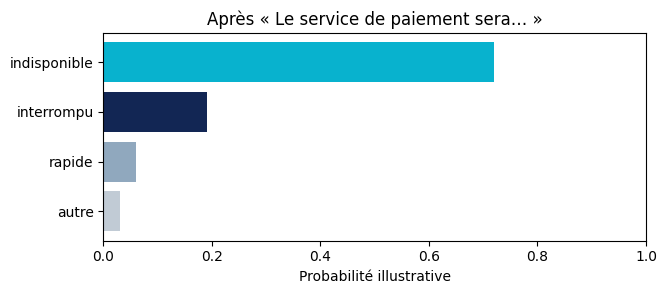

PPL (probabilités fictives) : 1.453


In [ ]:
# Reprendre la distribution illustrative du prochain token de la slide.
candidats = {"indisponible": .72, "interrompu": .19, "rapide": .06, "autre": .03}
fig, ax = plt.subplots(figsize=(7, 2.7))
ax.barh(list(candidats), list(candidats.values()), color=[CYAN, MARINE, "#90A8BE", "#C1CBD5"])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="Probabilité illustrative")
ax.set_title("Après « Le service de paiement sera… »")
plt.show()

# Pour calculer une PPL, on prend les probabilités des tokens observés
# à chaque position d'une séquence (ici, valeurs fictives).
probas_tokens_observes = np.array([0.72, 0.65, 0.80, 0.60])
ppl_illustrative = float(np.exp(-np.log(probas_tokens_observes).mean()))
afficher("PPL (probabilités fictives)", ppl_illustrative)

**Interprétation :** une **PPL plus faible** signifie que ce modèle attribue en moyenne davantage de probabilité aux tokens observés. Elle **ne dit pas** si le texte est vrai ou intéressant. La PPL dépend du modèle, du texte et de sa tokenisation : on ne compare pas arbitrairement les scores de modèles différents.

### 8/10 · Distinct-2 — Diversité des bigrammes

On calcule la part de **paires de mots consécutifs distinctes** dans un texte.

In [ ]:
# Les phrases reprennent les mots de la slide Distinct-2.
texte_repetitif = "service rapide service rapide service rapide"
texte_varie = "service rapide paiement fiable assistance disponible"

# Construire les bigrammes et compter les différents bigrammes.
def distinct_2(texte):
    mots = tokens(texte)
    bigrammes = list(zip(mots, mots[1:]))
    return len(set(bigrammes)) / len(bigrammes) if bigrammes else 0.0

for texte in [texte_repetitif, texte_varie]:
    print(f"{texte}\n   → Distinct-2 = {distinct_2(texte):.2f}\n")

service rapide service rapide service rapide
   → Distinct-2 = 0.40

service rapide paiement fiable assistance disponible
   → Distinct-2 = 1.00



**Interprétation :** le texte répétitif donne **0,40**, contre **1,00** pour le texte plus varié. Distinct-2 n'évalue ni le sens ni la qualité : un texte aléatoire peut aussi avoir beaucoup de bigrammes uniques.

### 9/10 · MAUVE — Comparer deux distributions de textes

MAUVE compare **un ensemble** de textes humains et **un ensemble** de textes générés à partir de représentations numériques. Le schéma suivant montre uniquement **deux nuages fictifs**, **pas un score MAUVE**.

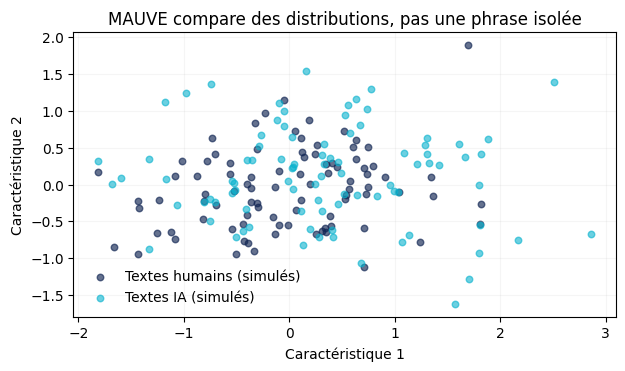

Aucun score MAUVE n'est calculé ici : ce graphique est conceptuel.


In [ ]:
# Simuler des caractéristiques 2D pour deux groupes de 90 textes.
# Cela illustre la différence des distributions ; aucun texte réel n'est encodé.
humains = rng.normal(loc=[0, 0], scale=[.85, .65], size=(90, 2))
generes_proches = rng.normal(loc=[.25, .12], scale=[.90, .68], size=(90, 2))

# Dessiner les deux distributions dans le même espace fictif.
fig, ax = plt.subplots(figsize=(7, 3.7))
ax.scatter(humains[:, 0], humains[:, 1], alpha=.65, s=22, color=MARINE, label="Textes humains (simulés)")
ax.scatter(generes_proches[:, 0], generes_proches[:, 1], alpha=.6, s=22, color=CYAN, label="Textes IA (simulés)")
ax.set(xlabel="Caractéristique 1", ylabel="Caractéristique 2")
ax.set_title("MAUVE compare des distributions, pas une phrase isolée")
ax.grid(alpha=.12)
ax.legend(frameon=False)
plt.show()
print("Aucun score MAUVE n'est calculé ici : ce graphique est conceptuel.")

**Interprétation :** des nuages proches représentent intuitivement des distributions similaires. Un **véritable MAUVE** nécessite des caractéristiques de texte issues d'un modèle et un algorithme de comparaison statistique ; une version facultative est proposée plus bas.

### 10/10 · G-Eval / LLM-as-a-Judge — Évaluation selon des critères

Un modèle évaluateur reçoit **la consigne + le texte généré + une grille de notation**. Les notes ci-dessous sont **attribuées fictivement**, comme sur la slide : **aucun modèle juge n'est appelé**.

In [ ]:
# Définir un exemple d'e-mail et quatre notes illustratives sur cinq.
consigne = "Informer les clients d'une maintenance du paiement entre 2 h et 2 h 30."
email = "Chers clients, les paiements seront indisponibles de 2 h à 2 h 30 pour maintenance."
notes_fictives = {"Clarté": 5, "Cohérence": 5, "Respect de la consigne": 4, "Exactitude factuelle": 3}

# Afficher la grille telle qu'un évaluateur pourrait la renseigner.
print("CONSIGNE :", consigne)
print("TEXTE :", email)
for critere, note in notes_fictives.items():
    print(f"{critere:<25} : {note}/5 (note fictive)")
print(f"Moyenne illustrative : {np.mean(list(notes_fictives.values())):.2f}/5")

# Ce prompt est prêt à être transmis à un LLM évaluateur, si un accès est disponible.
prompt_juge = f"""Évalue l'e-mail sur 5 pour : clarté, cohérence, respect de la consigne,
exactitude factuelle. Justifie brièvement chaque note et distingue les faits non vérifiables.
CONSIGNE : {consigne}
E-MAIL : {email}"""
print("\nEXTRAIT DU PROMPT POUR LE JUGE :\n", prompt_juge[:200] + "…")

CONSIGNE : Informer les clients d'une maintenance du paiement entre 2 h et 2 h 30.
TEXTE : Chers clients, les paiements seront indisponibles de 2 h à 2 h 30 pour maintenance.
Clarté                    : 5/5 (note fictive)
Cohérence                 : 5/5 (note fictive)
Respect de la consigne    : 4/5 (note fictive)
Exactitude factuelle      : 3/5 (note fictive)
Moyenne illustrative : 4.25/5

EXTRAIT DU PROMPT POUR LE JUGE :
 Évalue l'e-mail sur 5 pour : clarté, cohérence, respect de la consigne,
exactitude factuelle. Justifie brièvement chaque note et distingue les faits non vérifiables.
CONSIGNE : Informer les clients d'…


**Interprétation :** la grille rend les critères explicites, mais les notes ci-dessus ne sont **pas un véritable G-Eval**. G-Eval est un protocole de jugement par LLM ; ses résultats dépendent du modèle, des consignes et peuvent présenter des biais.

---
# 4. Tableau de synthèse

| Métrique | Idée clé | Ce que le code exécute |
|---|---|---|
| **ROUGE** | Recouvrement avec un résumé de référence | ✅ ROUGE-1 rappel simplifié |
| **BERTScore** | Proximité sémantique des tokens contextualisés | 🧪 Cosinus fictif ; vrai modèle facultatif |
| **QAFactEval** | Faits du résumé vérifiés par questions | 🧪 Réponses manuelles, principe illustré |
| **Exact Match** | Réponse identique après normalisation | ✅ Calcul exact sur les deux phrases |
| **Token F1** | Précision et rappel sur les tokens | ✅ Calcul de F1 |
| **Faithfulness** | Affirmations justifiées par les sources | ✅ Ratio, avec annotations manuelles |
| **Perplexity** | Capacité à prédire les tokens observés | ✅ Formule sur probabilités fictives ; vrai LM facultatif |
| **Distinct-2** | Part des bigrammes distincts | ✅ Calcul sur les textes d'exemple |
| **MAUVE** | Proximité entre distributions de textes | 🧪 Schéma illustratif ; calcul facultatif sur features synthétiques |
| **G-Eval** | Jugement par LLM selon critères explicites | 🧪 Grille et notes fictives, pas de juge appelé |

**Conclusion à donner à l'oral :** pour juger un système NLP, il faut associer **comparaison au texte**, **fidélité factuelle** et **évaluation qualitative**. Aucune métrique ne suffit seule.


---
# 5. Expériences facultatives (facultatif dans Colab)

Les cellules suivantes **ne sont pas nécessaires** à la compréhension du cours et restent désactivées par défaut. Elles demandent une connexion Internet pour télécharger des bibliothèques et des modèles. Active uniquement la démonstration souhaitée en passant son drapeau à `True`.

- **BERTScore** : vrai modèle multilingue.
- **Perplexity** : modèle de langue *distilgpt2* sur une phrase **anglaise** (modèle anglophone).
- **MAUVE** : algorithme réel sur **vecteurs artificiels** (et non sur de vrais textes).

Pour **QAFactEval** et **G-Eval**, ce notebook montre leur **logique d'évaluation**, sans prétendre exécuter leurs pipelines officiels.


In [ ]:
# Chaque expérience facultative est activée séparément.
RUN_BERTSCORE_REEL = False
RUN_PPL_REELLE = False
RUN_MAUVE_ALGO = False
print("Mode Colab standard prêt. Les téléchargements facultatifs sont désactivés.")

Mode Colab standard prêt. Les téléchargements facultatifs sont désactivés.


### Facultatif A — Vrai BERTScore (modèle préentraîné)

Cette expérience utilise le package `bert-score` et un modèle multilingue. Un téléchargement important et plusieurs minutes d'exécution sont possibles.

In [ ]:
if RUN_BERTSCORE_REEL:
    # Installer une bibliothèque réelle et télécharger un modèle BERT multilingue.
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "bert-score"])
    from bert_score import score as score_bert

    # Comparer deux résumés de sens proche.
    candidats = ["La société a supprimé 200 postes."]
    references = ["L’entreprise a licencié 200 employés."]
    p, r, f1_bert = score_bert(candidats, references, lang="fr", device="cpu", verbose=False)
    afficher("BERTScore F1 réel", f1_bert.item())
else:
    print("BERTScore réel ignoré (RUN_BERTSCORE_REEL=False).")

BERTScore réel ignoré (RUN_BERTSCORE_REEL=False).


### Facultatif B — Perplexité d'un modèle réel

`distilgpt2` est surtout conçu pour l'anglais. Pour comparer des phrases en français, il faudrait utiliser un modèle correctement entraîné sur cette langue et garder la même tokenisation.

In [ ]:
if RUN_PPL_REELLE:
    # Installer Transformers, puis récupérer un modèle auto-régressif.
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers", "torch"])
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM

    nom_modele = "distilgpt2"
    tokenizer = AutoTokenizer.from_pretrained(nom_modele)
    modele_lm = AutoModelForCausalLM.from_pretrained(nom_modele)
    modele_lm.eval()

    # Le modèle évalue la probabilité de chaque token du texte anglais observé.
    texte_en = "The payment service will be unavailable during maintenance."
    batch = tokenizer(texte_en, return_tensors="pt")
    with torch.no_grad():
        perte = modele_lm(**batch, labels=batch["input_ids"]).loss
    afficher("PPL réelle (distilgpt2)", float(torch.exp(perte)))
else:
    print("PPL réelle ignorée (RUN_PPL_REELLE=False).")

PPL réelle ignorée (RUN_PPL_REELLE=False).


### Facultatif C — Algorithme MAUVE sur des caractéristiques synthétiques

Cette cellule exécute le **véritable algorithme de calcul MAUVE**, mais sur des **features synthétiques** : le résultat ne mesure **pas** la qualité d'un générateur de texte. Le package peut être plus difficile à installer sur certaines versions de Colab.

In [ ]:
if RUN_MAUVE_ALGO:
    # Installer l'implémentation MAUVE, puis utiliser directement des features.
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mauve-text"])
    import mauve

    # Générer des représentations synthétiques de dimension plus élevée.
    p_features = rng.normal(0, 1, size=(160, 32)).astype("float32")
    q_features = rng.normal(.25, 1, size=(160, 32)).astype("float32")
    resultat = mauve.compute_mauve(
        p_features=p_features, q_features=q_features,
        num_buckets=10, verbose=False,
    )
    afficher("MAUVE (features fictives)", resultat.mauve)
else:
    print("MAUVE algorithmique ignoré (RUN_MAUVE_ALGO=False).")

MAUVE algorithmique ignoré (RUN_MAUVE_ALGO=False).


---
## Références

- [ROUGE — Lin (2004)](https://aclanthology.org/W04-1013/)
- [BERTScore — Zhang et al.](https://openreview.net/forum?id=SkeHuCVFDr)
- [QAFactEval — Fabbri et al.](https://aclanthology.org/2022.naacl-main.187/)
- [SQuAD — Exact Match et F1](https://aclanthology.org/D16-1264/)
- [RAGAS — Faithfulness](https://docs.ragas.io/en/latest/concepts/metrics/available_metrics/)
- [Distinct-n — Li et al.](https://aclanthology.org/N16-1014/)
- [MAUVE — publication et documentation](https://krishnap25.github.io/mauve/index.html)
- [G-Eval — Liu et al.](https://aclanthology.org/2023.emnlp-main.153/)

*Les données d'incidents, les extraits RH, les annotations et plusieurs scores sont fictifs. Ils servent à comprendre les métriques, non à évaluer un système de production.*